# 🎙️ Deepfake Audio Dataset Generator — Batch Edition
## Pipeline: `[REAL_A] ──► [SYNTHETIC_INSERT] ──► [REAL_B]`

**Características:**
- ✅ Procesa **carpetas completas** de audios en batch
- ✅ **Silero VAD** — detecta voz real, nunca corta mientras el usuario habla
- ✅ **XTTS v2** — clonación de voz de alta calidad
- ✅ Crossfade automático en las costuras
- ✅ Exporta pares etiquetados `real.wav` / `deepfake.wav` + `metadata.json`
- ✅ `dataset_index.csv` listo para entrenar

> ⚠️ Requiere GPU: `Runtime → Change runtime type → T4 GPU`

## 📦 Celda 1 — Instalación

In [ ]:
import sys
print(f"Python: {sys.version}")

# Limpiar todo lo anterior
!pip uninstall -y TTS coqui-tts 2>/dev/null

# Instalar directamente desde el commit estable de GitHub
!pip install -q git+https://github.com/idiap/coqui-ai-TTS.git
!pip install -q librosa soundfile pydub scipy matplotlib onnxruntime

#

!pip install -q openai-whisper

import torch
print(f"✅ PyTorch {torch.__version__} | CUDA: {torch.cuda.is_available()}")
if not torch.cuda.is_available():
    print("⚠️  Sin GPU — activa T4 en Runtime > Change runtime type")
else:
    print(f"   GPU: {torch.cuda.get_device_name(0)}")

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.2/56.2 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 997.3/997.3 kB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 639.3/639.3 kB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.5/163.5 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.1/71.1 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 82.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 18.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml)

## ⚙️ Celda 2 — Imports y Configuración

In [ ]:
import os, json, shutil, csv, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import librosa
import soundfile as sf
from pydub import AudioSegment
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, display
warnings.filterwarnings('ignore')

# ══════════════════════════════════════════════════════════
#  CONFIGURACIÓN — ajusta a tu gusto
# ══════════════════════════════════════════════════════════
CONFIG = {
    'input_dir':  '/content/audio_input',
    'output_dir': '/content/deepfake_dataset',
    'drive_dir':  '/content/drive/MyDrive/Datset_deekfake/xiaomi_12_x/speech_clean',  # ← nuevo

    'insert_phrases': [],  # ← vacío, ahora se extrae del audio real

    # Silero VAD
    'vad_threshold':      0.5,
    'min_silence_dur_ms': 400,
    'speech_pad_ms':      120,

    # Splice
    'crossfade_ms':     80,
    'sample_rate':      22050,
    'language':         'en',
    'phrases_per_audio': 1,   # ← 1 versión por audio

    'supported_exts': {'.wav', '.mp3', '.flac', '.ogg', '.m4a'},
}

os.makedirs(CONFIG['input_dir'],  exist_ok=True)
os.makedirs(CONFIG['output_dir'], exist_ok=True)
print("✅ Configuración lista")
print(f"   📂 Input:  {CONFIG['input_dir']}")
print(f"   📂 Output: {CONFIG['output_dir']}")


✅ Configuración lista
   📂 Input:  /content/audio_input
   📂 Output: /content/deepfake_dataset


Limpieza

In [ ]:
"""## 🧹 Celda 2.5 — Reset entre dispositivos (correr antes de subir audios nuevos)"""

import shutil

for d in [CONFIG['input_dir'], CONFIG['output_dir']]:
    if os.path.exists(d):
        shutil.rmtree(d)
    os.makedirs(d, exist_ok=True)

print("🧹 input_dir y output_dir limpiados — listo para el siguiente dispositivo")

🧹 input_dir y output_dir limpiados — listo para el siguiente dispositivo


## 📁 Celda 3 — Subir audios al input_dir

In [ ]:
from google.colab import files

print("Sube todos tus archivos de audio (WAV, MP3, FLAC...):")
uploaded = files.upload()

moved = []
for fname in uploaded:
    dest = os.path.join(CONFIG['input_dir'], fname)
    shutil.move(fname, dest)
    moved.append(dest)
    print(f"  ✅ {fname}")

print(f"\n📼 {len(moved)} archivo(s) listos en {CONFIG['input_dir']}")


Sube todos tus archivos de audio (WAV, MP3, FLAC...):


Saving speaker_3.wav to speaker_3.wav
  ✅ speaker_3.wav

📼 1 archivo(s) listos en /content/audio_input


## 🔬 Celda 4 — Cargar Silero VAD

In [ ]:
# Silero VAD — detecta voz con precisión de frame (10ms)
# No corta si el speaker está hablando
vad_model, vad_utils = torch.hub.load(
    repo_or_dir='snakers4/silero-vad',
    model='silero_vad',
    force_reload=False,
    onnx=True,               # más rápido en CPU
)
(get_speech_timestamps,
 save_audio,
 read_audio,
 VADIterator,
 collect_chunks) = vad_utils

print("✅ Silero VAD listo")


def get_silence_zones(audio_path, config):
    """
    Usa Silero VAD para obtener zonas de SILENCIO confirmado
    (donde NO hay voz). Nunca insertará en medio de habla.

    Retorna lista de dicts: {start_s, end_s, duration_s}
    """
    SAMPLING_RATE = 16000  # Silero requiere 16kHz

    wav = read_audio(audio_path, sampling_rate=SAMPLING_RATE)
    total_dur = len(wav) / SAMPLING_RATE

    speech_ts = get_speech_timestamps(
        wav,
        vad_model,
        threshold=config['vad_threshold'],
        sampling_rate=SAMPLING_RATE,
        min_silence_duration_ms=config['min_silence_dur_ms'],
        speech_pad_ms=config['speech_pad_ms'],
    )

    # Construir mapa de silencios = huecos entre segmentos de voz
    # Añadir padding al inicio y fin del audio
    pad = config['speech_pad_ms'] / 1000
    silence_zones = []

    # Antes del primer segmento de voz
    if speech_ts:
        first_start = speech_ts[0]['start'] / SAMPLING_RATE
        if first_start > pad:
            silence_zones.append({
                'start_s': round(pad, 3),
                'end_s':   round(first_start - pad, 3),
            })

    # Entre segmentos de voz consecutivos
    for i in range(len(speech_ts) - 1):
        end_prev  = speech_ts[i]['end']   / SAMPLING_RATE
        start_next = speech_ts[i+1]['start'] / SAMPLING_RATE
        gap_start = end_prev   + pad
        gap_end   = start_next - pad
        if gap_end - gap_start >= config['min_silence_dur_ms'] / 1000:
            silence_zones.append({
                'start_s': round(gap_start, 3),
                'end_s':   round(gap_end, 3),
            })

    # Después del último segmento
    if speech_ts:
        last_end = speech_ts[-1]['end'] / SAMPLING_RATE
        if total_dur - last_end > pad + 0.3:
            silence_zones.append({
                'start_s': round(last_end + pad, 3),
                'end_s':   round(total_dur - pad, 3),
            })

    # Calcular duración y filtrar mínimos
    min_dur = config['min_silence_dur_ms'] / 1000
    result = []
    for z in silence_zones:
        dur = z['end_s'] - z['start_s']
        if dur >= min_dur:
            z['duration_s'] = round(dur, 3)
            result.append(z)

    return result, total_dur


print("✅ Función get_silence_zones lista")


Using cache found in /root/.cache/torch/hub/snakers4_silero-vad_master


✅ Silero VAD listo
✅ Función get_silence_zones lista


In [ ]:
import glob

# Buscar el archivo en cualquier ubicación
matches = glob.glob(
    '/usr/**/TTS/tts/layers/tortoise/autoregressive.py',
    recursive=True
)

if not matches:
    print("⚠️  Archivo no encontrado — puede que no necesite parche")
else:
    filepath = matches[0]
    print(f"📄 Archivo encontrado: {filepath}")
    with open(filepath, "r") as f:
        content = f.read()

    old = "from transformers.pytorch_utils import isin_mps_friendly as isin"
    new = "from torch import isin"

    if old in content:
        content = content.replace(old, new)
        with open(filepath, "w") as f:
            f.write(content)
        print("✅ Parche aplicado correctamente")
    else:
        print("ℹ️  Ya estaba parcheado")

📄 Archivo encontrado: /usr/local/lib/python3.13/dist-packages/TTS/tts/layers/tortoise/autoregressive.py
ℹ️  Ya estaba parcheado


## 🤖 Celda 5 — Cargar XTTS v2 (clonación de voz)

In [ ]:
from TTS.api import TTS

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"🖥️  Usando: {DEVICE.upper()}")
print("⏳ Descargando XTTS v2 (~2 GB, solo la primera vez)...")

tts_model = TTS("tts_models/multilingual/multi-dataset/xtts_v2").to(DEVICE)
print("✅ XTTS v2 listo")


🖥️  Usando: CUDA
⏳ Descargando XTTS v2 (~2 GB, solo la primera vez)...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 255), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 255), got 50256. This may result in unexpected behavior.
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 607), got 50256. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 607), got 50256. This may result in unexpected behavior.


✅ XTTS v2 listo


## 🛠️ Celda 6 — Funciones del pipeline

In [ ]:
def select_insertion_zone(silence_zones):
    """Elige la zona más larga en el cuerpo del audio (evita inicio/fin 10%)."""
    if not silence_zones:
        return None
    total = silence_zones[-1]['end_s']
    margin = total * 0.10
    interior = [z for z in silence_zones
                if z['start_s'] > margin and z['end_s'] < total - margin]
    pool = interior if interior else silence_zones
    return max(pool, key=lambda z: z['duration_s'])


def generate_tts(tts_model, phrase, speaker_wav, language, out_path):
    """
    Extrae el fragmento más representativo del audio (10s del centro)
    como referencia para mejor clonación de voz.
    """
    # Extraer 10s del centro del audio como referencia
    y, sr = librosa.load(speaker_wav, sr=22050, mono=True)
    total_dur = len(y) / sr

    center     = total_dur / 2
    ref_start  = max(0, center - 5)
    ref_end    = min(total_dur, center + 5)
    ref_clip   = y[int(ref_start * sr):int(ref_end * sr)]

    ref_path = '/tmp/speaker_ref.wav'
    sf.write(ref_path, ref_clip, sr)

    tts_model.tts_to_file(
        text=phrase,
        speaker_wav=ref_path,
        language=language,
        file_path=out_path,
    )
    return out_path


def match_volume(synthetic, reference, start_ms, end_ms, max_gain=12):
    ctx_start = max(0, start_ms - 2000)
    ctx_end   = min(len(reference), end_ms + 2000)
    ctx = reference[ctx_start:ctx_end]

    if ctx.dBFS == float('-inf') or synthetic.dBFS == float('-inf'):
        return synthetic

    gain = float(np.clip(ctx.dBFS - synthetic.dBFS, -max_gain, max_gain))
    synthetic = synthetic.apply_gain(gain)

    ctx_samples   = np.array(ctx.get_array_of_samples(), dtype=np.float32)
    synth_samples = np.array(synthetic.get_array_of_samples(), dtype=np.float32)

    rms_ctx   = np.sqrt(np.mean(ctx_samples**2)) if len(ctx_samples) > 0 else 1
    rms_synth = np.sqrt(np.mean(synth_samples**2)) if len(synth_samples) > 0 else 1

    if rms_synth > 0:
        rms_gain  = rms_ctx / rms_synth
        adjusted  = synth_samples * rms_gain
        adjusted  = np.clip(adjusted, -32768, 32767).astype(np.int16)
        synthetic = synthetic._spawn(adjusted.tobytes())

    return synthetic


def splice_audio(original_path, synthetic_path, zone, crossfade_ms,
                 output_path, sample_rate):
    """[REAL_A] + [SYNTHETIC] + [REAL_B] con crossfade suave."""
    original  = AudioSegment.from_file(original_path).set_frame_rate(sample_rate).set_channels(1)
    synthetic = AudioSegment.from_file(synthetic_path).set_frame_rate(sample_rate).set_channels(1)

    start_ms = int(zone['start_s'] * 1000)
    end_ms   = int(zone['end_s']   * 1000)
    real_A   = original[:start_ms]
    real_B   = original[end_ms:]

    synthetic = match_volume(synthetic, original, start_ms, end_ms)

    cf = min(crossfade_ms,
             max(1, len(real_A) - 1),
             max(1, len(synthetic) // 2 - 1),
             max(1, len(real_B) - 1))

    spliced = real_A.append(synthetic, crossfade=cf).append(real_B, crossfade=cf)
    spliced.export(output_path, format='wav')

    return {
        'real_A_s':       round(len(real_A)    / 1000, 3),
        'synthetic_s':    round(len(synthetic) / 1000, 3),
        'real_B_s':       round(len(real_B)    / 1000, 3),
        'total_s':        round(len(spliced)   / 1000, 3),
        'crossfade_ms':   cf,
        'insert_start_s': zone['start_s'],
        'insert_end_s':   zone['end_s'],
    }


def visualize_splice(real_path, fake_path, zone, splice_info, out_dir):
    y_r, sr = librosa.load(real_path, sr=None)
    y_f, _  = librosa.load(fake_path, sr=sr)
    ins_end  = zone['start_s'] + splice_info['synthetic_s']

    fig, axes = plt.subplots(4, 1, figsize=(15, 12))
    fig.suptitle('Real vs Deepfake', fontsize=14, fontweight='bold')

    for ax, y, label, color in [
        (axes[0], y_r, 'Waveform REAL',     'steelblue'),
        (axes[1], y_f, 'Waveform DEEPFAKE', 'crimson'),
    ]:
        t = np.linspace(0, len(y)/sr, len(y))
        ax.plot(t, y, color=color, linewidth=0.4, alpha=0.8)
        ax.set_title(label, color=color, fontsize=10)
        ax.axvspan(zone['start_s'], ins_end, alpha=0.25, color='red', label='Inserción')
        ax.legend(fontsize=7)

    for ax, y, label, color in [
        (axes[2], y_r, 'Espectrograma REAL',     'steelblue'),
        (axes[3], y_f, 'Espectrograma DEEPFAKE', 'crimson'),
    ]:
        D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
        img = librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='hz',
                                       ax=ax, cmap='magma')
        ax.set_title(label, color=color, fontsize=10)
        ax.axvline(zone['start_s'], color='yellow', lw=1.5, ls='--')
        ax.axvline(ins_end,         color='yellow', lw=1.5, ls='--')
        plt.colorbar(img, ax=ax, format='%+2.0f dB')

    plt.tight_layout()
    out = os.path.join(out_dir, 'comparison.png')
    plt.savefig(out, dpi=120, bbox_inches='tight')
    plt.close()
    return out


def visualize_ia_segment(real_path, ia_segment_path, out_dir):
    y_r, sr = librosa.load(real_path,       sr=None)
    y_s, _  = librosa.load(ia_segment_path, sr=sr)

    fig, axes = plt.subplots(4, 1, figsize=(15, 12))
    fig.suptitle('Real vs IA_segment', fontsize=14, fontweight='bold')

    for ax, y, label, color in [
        (axes[0], y_r, 'Waveform REAL',       'steelblue'),
        (axes[1], y_s, 'Waveform IA_segment', 'darkorange'),
    ]:
        t = np.linspace(0, len(y)/sr, len(y))
        ax.plot(t, y, color=color, linewidth=0.4, alpha=0.8)
        ax.set_title(label, color=color, fontsize=10)
        ax.set_ylabel('Amp')

    for ax, y, label, color in [
        (axes[2], y_r, 'Espectrograma REAL',       'steelblue'),
        (axes[3], y_s, 'Espectrograma IA_segment', 'darkorange'),
    ]:
        D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
        img = librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='hz',
                                       ax=ax, cmap='magma')
        ax.set_title(label, color=color, fontsize=10)
        plt.colorbar(img, ax=ax, format='%+2.0f dB')

    plt.tight_layout()
    out = os.path.join(out_dir, 'comparison_ia_segment.png')
    plt.savefig(out, dpi=120, bbox_inches='tight')
    plt.close()
    print(f"📊 Espectrograma IA_segment guardado")
    return out


print("✅ Funciones listas")

✅ Funciones listas


## 🚀 Celda 7 — Batch Pipeline (procesa toda la carpeta)

In [ ]:
import random
import whisper
import librosa.display

print("⏳ Cargando Whisper...")
whisper_model = whisper.load_model("base")
print("✅ Whisper listo")


def transcribe_segment(audio_path, start_s, end_s, sr=16000):
    y, _ = librosa.load(audio_path, sr=sr)
    segment = y[int(start_s * sr):int(end_s * sr)]
    if len(segment) < sr * 0.5:
        return None
    tmp = '/tmp/seg_transcribe.wav'
    sf.write(tmp, segment, sr)
    result = whisper_model.transcribe(tmp, language=CONFIG['language'])
    phrase = result['text'].strip()
    return phrase if phrase and len(phrase) > 3 else None


def pick_two_speech_zones(audio_path, config):
    SAMPLING_RATE = 16000
    wav = read_audio(audio_path, sampling_rate=SAMPLING_RATE)
    total_dur = len(wav) / SAMPLING_RATE

    speech_ts = get_speech_timestamps(
        wav, vad_model,
        threshold=config['vad_threshold'],
        sampling_rate=SAMPLING_RATE,
        min_silence_duration_ms=config['min_silence_dur_ms'],
        speech_pad_ms=config['speech_pad_ms'],
    )

    if len(speech_ts) < 2:
        return None, None

    speech_zones = [{
        'start_s': round(s['start'] / SAMPLING_RATE, 3),
        'end_s':   round(s['end']   / SAMPLING_RATE, 3),
        'dur_s':   round((s['end'] - s['start']) / SAMPLING_RATE, 3),
    } for s in speech_ts]

    valid_A = [z for z in speech_zones if z['dur_s'] >= 5.0]
    valid_B = [z for z in speech_zones if z['dur_s'] >= 5.0]

    if not valid_A or not valid_B:
        return None, None

    mid = total_dur / 2
    first_half  = [z for z in valid_A if z['end_s'] < mid]
    second_half = [z for z in valid_B if z['start_s'] > mid]

    if not first_half or not second_half:
        zone_A = valid_A[0]
        zone_B = valid_B[-1]
    else:
        zone_A = random.choice(first_half)
        zone_B = random.choice(second_half)

    if abs(zone_B['start_s'] - zone_A['end_s']) < 5.0:
        return None, None

    return zone_A, zone_B


def generate_vad_visualization(audio_path, silence_zones, total_dur, out_dir):
    """Figura 2 — Waveform con zonas de silencio VAD marcadas."""
    y, sr = librosa.load(audio_path, sr=None)
    t = np.linspace(0, len(y)/sr, len(y))
    fig, ax = plt.subplots(figsize=(14, 3))
    ax.plot(t, y, color='steelblue', linewidth=0.4, alpha=0.85)
    for i, z in enumerate(silence_zones):
        ax.axvspan(z['start_s'], z['end_s'],
                   alpha=0.30, color='tomato',
                   label='Silencio VAD' if i == 0 else '')
    ax.set_title(f'Detección de zonas de silencio — Silero VAD | {os.path.basename(audio_path)}',
                 fontsize=11)
    ax.set_xlabel('Tiempo (s)')
    ax.set_ylabel('Amplitud')
    ax.legend(fontsize=8)
    ax.set_xlim(0, total_dur)
    plt.tight_layout()
    out = os.path.join(out_dir, 'fig2_vad_zones.png')
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.close()
    print(f"   📊 Fig 2 guardada: fig2_vad_zones.png")
    return out


def generate_summary_figure(audio_path, splicing_path, zone_splice, info, out_dir):
    """Figura 3 — Espectrograma comparativo real vs Splicing_IA."""
    y_r, sr = librosa.load(audio_path,    sr=None)
    y_f, _  = librosa.load(splicing_path, sr=sr)
    ins_end  = zone_splice['start_s'] + info['synthetic_s']

    fig, axes = plt.subplots(4, 1, figsize=(14, 12))
    fig.suptitle(f'Audio real vs Splicing_IA — {os.path.basename(audio_path)}',
                 fontsize=12, fontweight='bold')

    for ax, y, label, color in [
        (axes[0], y_r, 'Waveform — REAL',        'steelblue'),
        (axes[1], y_f, 'Waveform — SPLICING_IA', 'crimson'),
    ]:
        t = np.linspace(0, len(y)/sr, len(y))
        ax.plot(t, y, color=color, linewidth=0.4, alpha=0.85)
        ax.set_title(label, color=color, fontsize=10)
        ax.set_ylabel('Amp')
        ax.axvspan(zone_splice['start_s'], ins_end,
                   alpha=0.22, color='red', label='Fragmento sintético')
        ax.legend(fontsize=7)

    for ax, y, label, color in [
        (axes[2], y_r, 'Espectrograma — REAL',        'steelblue'),
        (axes[3], y_f, 'Espectrograma — SPLICING_IA', 'crimson'),
    ]:
        D   = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
        img = librosa.display.specshow(D, sr=sr, x_axis='time',
                                       y_axis='hz', ax=ax, cmap='magma')
        ax.set_title(label, color=color, fontsize=10)
        ax.axvline(zone_splice['start_s'], color='yellow', lw=1.5,
                   ls='--', label='Inicio empalme')
        ax.axvline(ins_end, color='orange', lw=1.5,
                   ls='--', label='Fin empalme')
        ax.legend(fontsize=7)
        plt.colorbar(img, ax=ax, format='%+2.0f dB')

    plt.tight_layout()
    out = os.path.join(out_dir, 'fig3_comparativo.png')
    plt.savefig(out, dpi=150, bbox_inches='tight')
    plt.close()
    print(f"   📊 Fig 3 guardada: fig3_comparativo.png")
    return out


def process_one(audio_path, tts_model, config, rows):
    fname = Path(audio_path).stem
    sdir  = os.path.join(config['output_dir'], fname)
    os.makedirs(sdir, exist_ok=True)

    # 1. VAD
    silences, total_dur = get_silence_zones(audio_path, config)
    if not silences:
        return None, f"Sin silencios VAD ≥{config['min_silence_dur_ms']}ms"

    # 2. Zona de splice — rango central 25%-75%
    range_start = total_dur * 0.25
    range_end   = total_dur * 0.75
    center_silences = [z for z in silences
                       if z['start_s'] >= range_start and z['end_s'] <= range_end]
    zone_splice = random.choice(center_silences) if center_silences else random.choice(silences)

    # 3. Dos zonas de voz separadas
    zone_A, zone_B = pick_two_speech_zones(audio_path, config)
    if zone_A is None:
        return None, "No se encontraron dos zonas de voz separadas (zona_A necesita ≥5s)"

    # 4. Transcribir frases
    phrase_A = transcribe_segment(audio_path, zone_A['start_s'], zone_A['end_s'])
    if not phrase_A:
        phrase_A = "This is a test sentence"
    phrase_B = transcribe_segment(audio_path, zone_B['start_s'], zone_B['end_s'])
    if not phrase_B:
        phrase_B = "Another test sentence here"

    print(f"   📝 Frase deepfake  (zona A): \"{phrase_A[:60]}\"")
    print(f"   📝 Frase IA_segment (zona B): \"{phrase_B[:60]}\"")

    # 5. Generar Splicing_IA
    splicing_path = os.path.join(sdir, 'Splicing_IA.wav')
    synth_A_tmp   = os.path.join(sdir, '_tmp_synth_A.wav')
    generate_tts(tts_model, phrase_A, audio_path, config['language'], synth_A_tmp)

    info = splice_audio(
        original_path=audio_path,
        synthetic_path=synth_A_tmp,
        zone=zone_splice,
        crossfade_ms=config['crossfade_ms'],
        output_path=splicing_path,
        sample_rate=config['sample_rate'],
    )
    os.remove(synth_A_tmp)

    # 6. Generar IA_segment y normalizar volumen
    ia_segment_path = os.path.join(sdir, 'IA_segment.wav')
    generate_tts(tts_model, phrase_B, audio_path, config['language'], ia_segment_path)

    original_ref = AudioSegment.from_file(audio_path).set_frame_rate(config['sample_rate']).set_channels(1)
    ia_seg_audio = AudioSegment.from_file(ia_segment_path).set_frame_rate(config['sample_rate']).set_channels(1)
    ia_seg_norm  = match_volume(ia_seg_audio, original_ref, 0, len(original_ref))
    ia_seg_norm.export(ia_segment_path, format='wav')

    # 7. Figura 2 — VAD
    try:
        generate_vad_visualization(audio_path, silences, total_dur, sdir)
    except Exception:
        pass

    # 8. Figura 3 — Comparativo real vs Splicing_IA
    try:
        generate_summary_figure(audio_path, splicing_path, zone_splice, info, sdir)
    except Exception:
        pass

    # 9. Espectrograma IA_segment
    try:
        visualize_ia_segment(audio_path, ia_segment_path, sdir)
    except Exception:
        pass

    # 10. Metadata
    meta = {
        'sample_id':   fname,
        'source_file': os.path.basename(audio_path),
        'language':    config['language'],
        'tts_model':   'xtts_v2',
        'total_dur_s': total_dur,
        'splice': {
            'zone':        zone_splice,
            'phrase':      phrase_A,
            'phrase_zone': zone_A,
            'splice_info': info,
        },
        'ia_segment': {
            'phrase':      phrase_B,
            'phrase_zone': zone_B,
        },
        'structure': [
            {'part': 'real_A',    'start_s': 0,
             'end_s': zone_splice['start_s'], 'label': 'real'},
            {'part': 'synthetic', 'start_s': zone_splice['start_s'],
             'end_s': zone_splice['start_s'] + info['synthetic_s'], 'label': 'synthetic'},
            {'part': 'real_B',
             'start_s': zone_splice['start_s'] + info['synthetic_s'],
             'end_s': info['total_s'], 'label': 'real'},
        ],
    }
    with open(os.path.join(sdir, 'metadata.json'), 'w') as f:
        json.dump(meta, f, indent=2)

    # 11. CSV
    rows.append({
        'sample_id':         fname,
        'Splicing_IA_path':  splicing_path,
        'IA_segment_path':   ia_segment_path,
        'source_file':       os.path.basename(audio_path),
        'phrase_splicing':   phrase_A,
        'phrase_ia_segment': phrase_B,
        'splice_start_s':    zone_splice['start_s'],
        'splice_end_s':      zone_splice['end_s'],
        'synthetic_dur_s':   info['synthetic_s'],
        'total_dur_s':       info['total_s'],
    })
    return sdir, None


def run_batch(config, tts_model):
    import gc
    audio_files = sorted([
        str(f) for f in Path(config['input_dir']).iterdir()
        if f.suffix.lower() in config['supported_exts']
    ])
    if not audio_files:
        print(f"❌ No hay audios en {config['input_dir']}")
        return []

    rows   = []
    errors = []
    total  = len(audio_files)

    print(f"📼 Audios a procesar: {total}")
    print("─" * 55)

    for i, audio_path in enumerate(audio_files):
        aname = os.path.basename(audio_path)
        print(f"\n[{i+1}/{total}] 📼 {aname}")
        try:
            _, err = process_one(audio_path, tts_model, config, rows)
            print("   ⚠️  " + err if err else "   ✅ Listo")
            if err:
                errors.append({'file': aname, 'error': err})
        except Exception as e:
            print(f"   ❌ {e}")
            errors.append({'file': aname, 'error': str(e)})
        finally:
            gc.collect()
            torch.cuda.empty_cache()
            print(f"   🧹 Memoria liberada")

    # CSV
    csv_path = os.path.join(config['output_dir'], 'dataset_index.csv')
    if rows:
        with open(csv_path, 'w', newline='') as f:
            w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
            w.writeheader()
            w.writerows(rows)

    print("\n" + "═" * 55)
    print(f"✅ Procesados: {len(rows)}/{total}")
    print(f"❌ Errores:    {len(errors)}")

    return rows


# ▶ EJECUTAR
dataset = run_batch(CONFIG, tts_model)

⏳ Cargando Whisper...
✅ Whisper listo
📼 Audios a procesar: 1
───────────────────────────────────────────────────────

[1/1] 📼 speaker_3.wav
   📝 Frase deepfake  (zona A): "She can scoop these things into three red bags and we will g"
   📝 Frase IA_segment (zona B): "These take the shape of a long round arch with its path high"
   📊 Fig 2 guardada: fig2_vad_zones.png
   📊 Fig 3 guardada: fig3_comparativo.png
📊 Espectrograma IA_segment guardado
   ✅ Listo
   🧹 Memoria liberada

═══════════════════════════════════════════════════════
✅ Procesados: 1/1
❌ Errores:    0


   📊 Fig 2 guardada: fig2_vad_zones.png
   📊 Fig 3 guardada: fig3_comparativo.png

📊 Figura 2 — Zonas de silencio VAD:


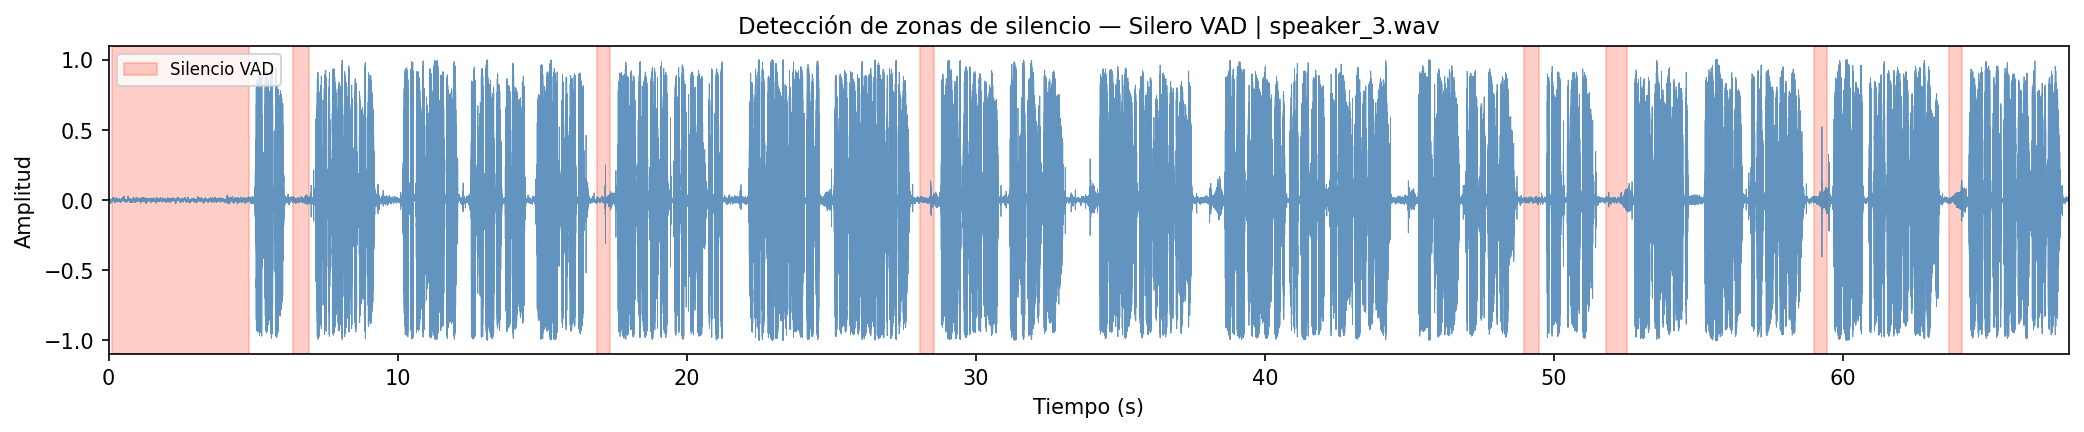


📊 Figura 3 — Comparativo real vs Splicing_IA:


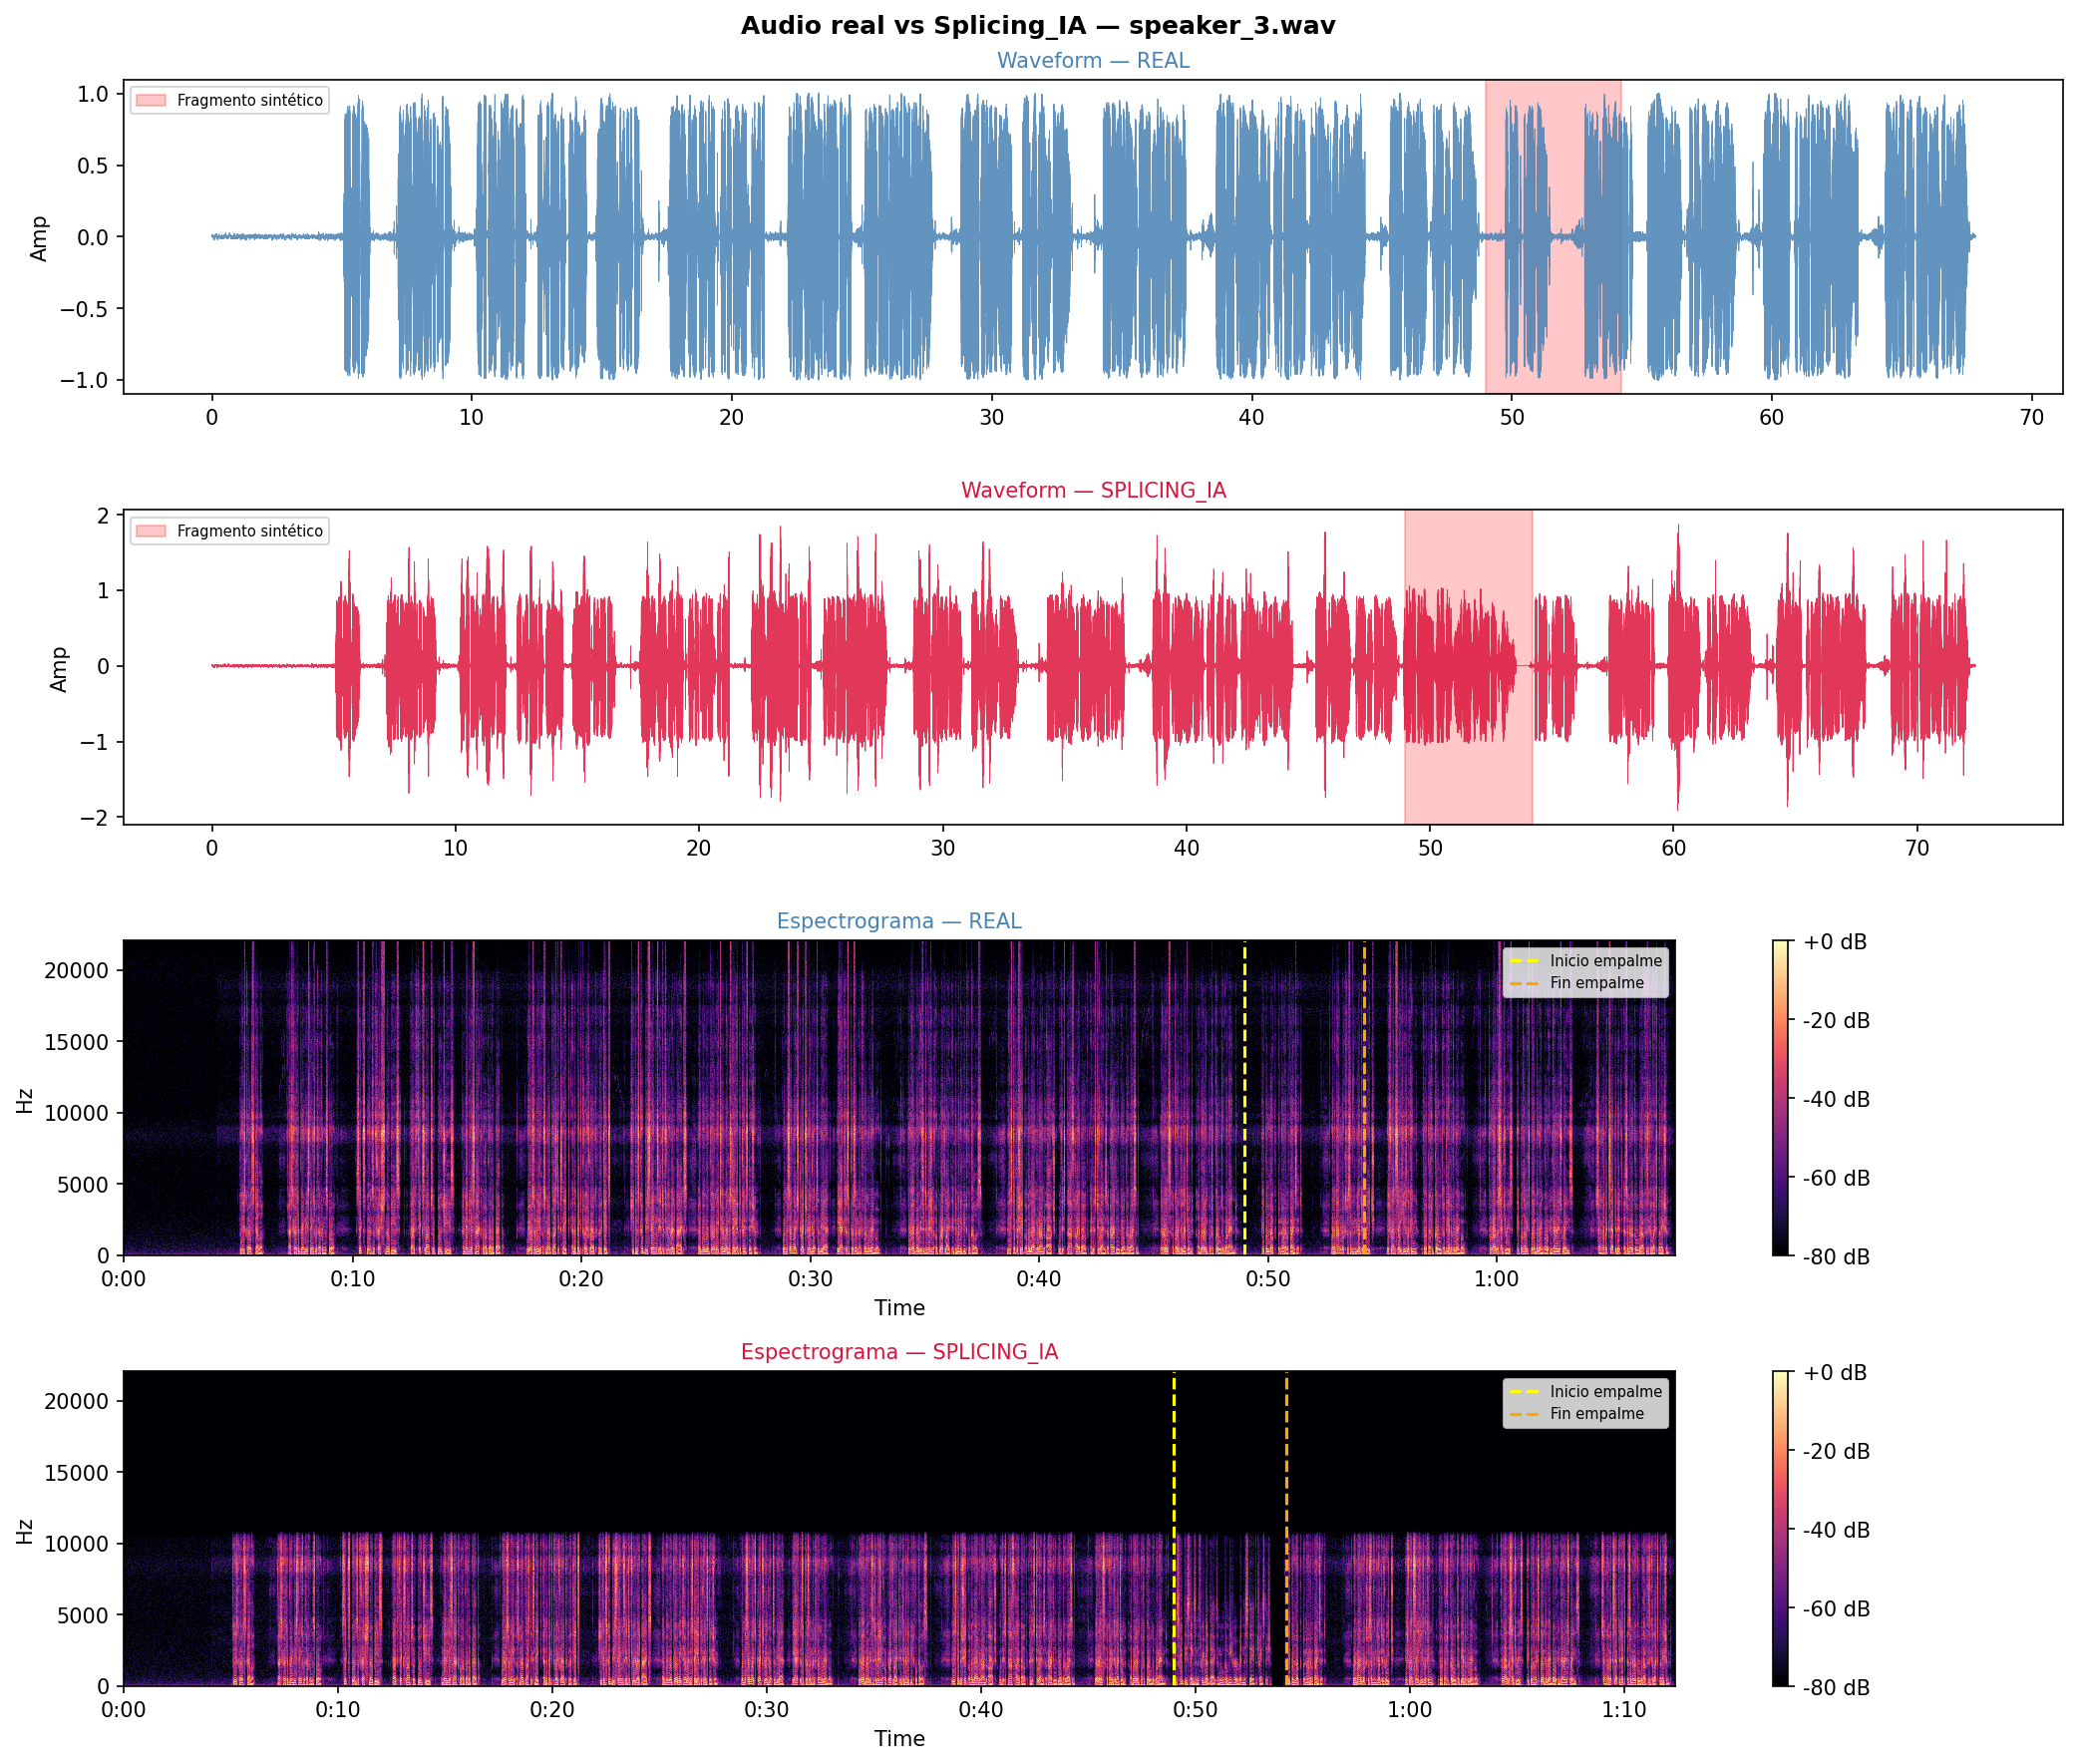

In [ ]:
# ── Generar imágenes para el informe ──────────────────
# Cambia este nombre por el audio que ya procesaste
AUDIO_NAME = 'speaker_3'  # sin extensión

audio_path    = os.path.join(CONFIG['input_dir'],  AUDIO_NAME + '.wav')
splicing_path = os.path.join(CONFIG['output_dir'], AUDIO_NAME, 'Splicing_IA.wav')
sdir          = os.path.join(CONFIG['output_dir'], AUDIO_NAME)

# Verificar que existen
if not os.path.exists(audio_path):
    print(f"❌ No se encontró: {audio_path}")
elif not os.path.exists(splicing_path):
    print(f"❌ No se encontró: {splicing_path}")
else:
    # VAD para obtener silencios
    silences, total_dur = get_silence_zones(audio_path, CONFIG)

    # Leer metadata para obtener zona de splice
    import json
    with open(os.path.join(sdir, 'metadata.json')) as f:
        meta = json.load(f)

    zone_splice = meta['splice']['zone']
    info        = meta['splice']['splice_info']

    # Generar figuras
    generate_vad_visualization(audio_path, silences, total_dur, sdir)
    generate_summary_figure(audio_path, splicing_path, zone_splice, info, sdir)

    # Mostrar en Colab
    from IPython.display import Image as IPImage
    print("\n📊 Figura 2 — Zonas de silencio VAD:")
    display(IPImage(os.path.join(sdir, 'fig2_vad_zones.png')))

    print("\n📊 Figura 3 — Comparativo real vs Splicing_IA:")
    display(IPImage(os.path.join(sdir, 'fig3_comparativo.png')))

## 🔊 Celda 8 — Preview de un par generado

In [ ]:
import pandas as pd

csv_path = os.path.join(CONFIG['output_dir'], 'dataset_index.csv')
df = pd.read_csv(csv_path)
print(f"📊 Dataset: {len(df)} filas")
display(df.head(10))

if len(df) > 0:
    row = df.iloc[0]
    print(f"\n🎯 Muestra: {row['sample_id']}")
    print(f"   Frase Splicing_IA:  \"{row['phrase_splicing']}\"")
    print(f"   Frase IA_segment:   \"{row['phrase_ia_segment']}\"")
    print(f"   Inserción: {row['splice_start_s']}s → {row['splice_end_s']}s")
    print(f"   Sintético: {row['synthetic_dur_s']}s")

    # Escuchar Splicing_IA
    y_f, sr = librosa.load(row['Splicing_IA_path'], sr=None)
    print("\n▶️ Splicing_IA [real_A + IA + real_B]:")
    display(Audio(y_f, rate=sr))

    # Escuchar IA_segment
    y_s, sr_s = librosa.load(row['IA_segment_path'], sr=None)
    print("\n▶️ IA_segment (fragmento IA independiente):")
    display(Audio(y_s, rate=sr_s))

    # Espectrograma deepfake
    spec1 = os.path.join(CONFIG['output_dir'], row['sample_id'], 'comparison.png')
    if os.path.exists(spec1):
        from IPython.display import Image as IPImage
        print("\n📊 Espectrograma Splicing_IA:")
        display(IPImage(spec1))

    # Espectrograma IA_segment
    spec2 = os.path.join(CONFIG['output_dir'], row['sample_id'], 'comparison_ia_segment.png')
    if os.path.exists(spec2):
        print("\n📊 Espectrograma IA_segment:")
        display(IPImage(spec2))

📊 Dataset: 1 filas


,sample_id,Splicing_IA_path,IA_segment_path,source_file,phrase_splicing,phrase_ia_segment,splice_start_s,splice_end_s,synthetic_dur_s,total_dur_s
0,speaker_3,/content/deepfake_dataset/speaker_3/Splicing_I...,/content/deepfake_dataset/speaker_3/IA_segment...,speaker_3.wav,"6 spoons of fresh snow peas, 5-6 lbs of blue c...",When a man looks for something beyond his reac...,28.08,28.56,5.985,73.164



🎯 Muestra: speaker_3
   Frase Splicing_IA:  "6 spoons of fresh snow peas, 5-6 lbs of blue cheese and maybe a snack for her brother, babe."
   Frase IA_segment:   "When a man looks for something beyond his reach, his friends say he's looking for the part of gold at the end of the rainbow."
   Inserción: 28.08s → 28.56s
   Sintético: 5.985s

▶️ Splicing_IA [real_A + IA + real_B]:



▶️ IA_segment (fragmento IA independiente):



📊 Espectrograma IA_segment:


NameError: name 'IPImage' is not defined

## 📥 Celda 9 — Descargar dataset completo

In [ ]:
import zipfile
from google.colab import files

zip_path = '/content/deepfake_dataset.zip'
print("📦 Comprimiendo dataset...")

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, fnames in os.walk(CONFIG['output_dir']):
        for fname in fnames:
            fpath = os.path.join(root, fname)
            arc   = os.path.relpath(fpath, CONFIG['output_dir'])
            zf.write(fpath, arc)

size_mb = os.path.getsize(zip_path) / (1024**2)
print(f"✅ ZIP: {zip_path} ({size_mb:.1f} MB)")
files.download(zip_path)


📦 Comprimiendo dataset...
✅ ZIP: /content/deepfake_dataset.zip (2.6 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>